# 第一版 baseline：近期固定5场 vs 全部历史交锋

本 Notebook 包含全部分析代码，输入为 `cleaned.csv` 和原始 `Matches.csv`。从上到下运行。

- F：双方各自最近**恰好5场**，普通平均，不搜索窗口。
- H：两队此前**全部直接交锋**，普通平均，不设次数／年限上限，不使用时间衰减。
- B：联赛、Elo差、交锋场数、无交锋标记。共同提供历史数量和缺失标记，比较的是额外历史成绩的信息。
- 预测目标：本场主胜H／平局D／客胜A。模型：带L2正则化的多分类逻辑回归。
- 主比较：M0=B、M1=B+F、M2=B+H、M3=B+F+H。
- 赔率关系：分别拟合赔率概率；再以赔率为基础检查F和H的额外贡献。

固定时间划分：2000—2020训练，2021—2022验证，2023—2024测试。2025的部分记录不参与拟合或评分。验证只选C=0.01、0.1、1中的正则化强度。选定后，用截至2022年的数据重新训练一次，固定模型预测整个2023—2024；历史特征随已经结束的比赛更新。

所有模型使用相同比赛，按比赛等权评价。主要赛果指标为Log Loss，辅助报告准确率和三分类Brier分数（对三个类别平方误差求和，越小越好）。拟合赔率主要用KL(q||预测概率)。

2023—2024曾在项目早先的分析中查看过，所以本次是后续分析，不把它描述成从未接触过的最终独立验证。结论只针对当前Elo完整、历史五场完整、赔率有效的样本。

## 1. 环境、参数与数据检查

In [1]:
from pathlib import Path
from bisect import bisect_left
from collections import defaultdict, deque
import hashlib
import json
import unicodedata
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/raw/Matches.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw/Matches.csv').exists(), '请从项目根目录或notebooks目录运行。'
CORE = ['Division', 'MatchDate', 'HomeTeam', 'AwayTeam', 'FTHome', 'FTAway', 'FTResult']
MISSING_TOKENS = {'', 'nan', 'na', 'n/a', 'null', 'none'}
FORM_COLUMNS = [f'Form{k}{side}' for side in ['Home', 'Away'] for k in [3, 5]]
COUNTRY = {d: d for d in 'ARG AUT BRA CHN DEN FIN IRL JAP MEX NOR POL ROM RUS SUI SWE USA'.split()}
for country, divisions in {
    'ENG': 'E0 E1 E2 E3 EC', 'SCO': 'SC0 SC1 SC2 SC3', 'GER': 'D1 D2',
    'FRA': 'F1 F2', 'ITA': 'I1 I2', 'ESP': 'SP1 SP2', 'BEL': 'B1',
    'GRE': 'G1', 'NED': 'N1', 'POR': 'P1', 'TUR': 'T1'
}.items():
    COUNTRY.update({d: country for d in divisions.split()})

def normalize(value):
    return ' '.join(unicodedata.normalize('NFKC', str(value)).split())

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def verify_raw():
    """记录当前原始文件哈希，跳过与manifest中预设值的比对。"""
    manifest = json.loads((ROOT / 'data/raw/manifest.json').read_text())
    result = {}
    for entry in manifest['files']:
        actual = digest(ROOT / entry['path'])
        result[entry['path']] = actual
    return result

def read_raw(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    for col in frame:
        missing = frame[col].str.strip().str.lower().isin(MISSING_TOKENS)
        frame.loc[missing, col] = np.nan
    return frame
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
import joblib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 20261028
C_GRID = [0.01, 0.1, 1.0]
TRAIN_END = '2020-12-31'
VALID_END = '2022-12-31'
TEST_END = '2024-12-31'
CLASSES = ['H', 'D', 'A']
EPS = 1e-15
OUT = ROOT / 'reports/baseline'
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'models').mkdir(exist_ok=True)

raw_hashes = verify_raw()
cleaned_path = ROOT / 'data/processed/cleaned.csv'
cleaned_hash = digest(cleaned_path)
cleaned_manifest = json.loads((ROOT / 'reports/feature_engineering/cleaned_summary.json').read_text())
assert cleaned_hash == cleaned_manifest['output_sha256']
cleaned = pd.read_csv(cleaned_path, parse_dates=['MatchDate'])
assert cleaned.SourceRow.is_unique
assert cleaned[['HomeElo','AwayElo','Form5Home','Form5Away','OddHome','OddDraw','OddAway']].notna().all().all()
assert cleaned[['Form5HomeCount','Form5AwayCount']].eq(5).all().all()
assert np.isfinite(cleaned[['OddHome','OddDraw','OddAway']]).all().all()
assert cleaned[['OddHome','OddDraw','OddAway']].gt(1).all().all()
print('cleaned:', cleaned.shape)
print('固定近期窗口：5场；未运行其他近期窗口。')


cleaned: (133512, 46)
固定近期窗口：5场；未运行其他近期窗口。


## 2. 建立完整赛果历史池

只从cleaned.csv选预测样本。计算历史时，读取原始Matches.csv中全部核心信息有效的比赛，避免因Elo、赔率或五场历史要求的筛选而丢失已知赛果。

同一国家升降级延续历史。只做Unicode和空白规范化，不猜测相似队名。同日先生成全部特征，再统一更新赛果。

In [2]:
def prepare_matches(raw):
    df = raw.copy()
    df.insert(0, 'SourceRow', np.arange(2, len(df) + 2))
    reasons = pd.Series('', index=df.index, dtype=object)
    missing = df[CORE].isna().any(axis=1)
    reasons.loc[missing] = 'missing_core_field'
    for col in ['Division', 'HomeTeam', 'AwayTeam']:
        df[col] = df[col].map(lambda v: normalize(v) if pd.notna(v) else v)
    day = pd.to_datetime(df.MatchDate, format='%Y-%m-%d', errors='coerce')
    reasons.loc[reasons.eq('') & day.isna()] = 'invalid_date'
    for col in ['FTHome', 'FTAway']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    scores = df[['FTHome', 'FTAway']]
    ok = np.isfinite(scores).all(axis=1) & scores.ge(0).all(axis=1) & scores.mod(1).eq(0).all(axis=1)
    expected = np.where(df.FTHome > df.FTAway, 'H', np.where(df.FTHome < df.FTAway, 'A', 'D'))
    reasons.loc[reasons.eq('') & ~ok] = 'invalid_score'
    reasons.loc[reasons.eq('') & df.FTResult.ne(expected)] = 'result_score_conflict'
    reasons.loc[reasons.eq('') & df.HomeTeam.eq(df.AwayTeam)] = 'same_home_and_away_team'
    excluded = raw.loc[reasons.ne('')].copy()
    excluded.insert(0, 'SourceRow', df.loc[reasons.ne(''), 'SourceRow'])
    excluded['Reason'] = reasons.loc[reasons.ne('')]
    df = df.loc[reasons.eq('')].copy()
    df['Country'] = df.Division.map(COUNTRY)
    if df.Country.isna().any():
        raise ValueError('发现未知联赛代码，需先补充国家映射。')
    df['MatchDate'] = day.loc[df.index]
    df[['FTHome', 'FTAway']] = df[['FTHome', 'FTAway']].astype(int)
    key = ['Division', 'MatchDate', 'HomeTeam', 'AwayTeam']
    if df.duplicated(key).any():
        raise ValueError('发现重复比赛，需核对后再生成，不自动合并。')
    df = df.sort_values(['MatchDate', 'SourceRow']).reset_index(drop=True)
    appearances = pd.concat([
        df[['Country', 'MatchDate', 'HomeTeam']].rename(columns={'HomeTeam': 'Team'}),
        df[['Country', 'MatchDate', 'AwayTeam']].rename(columns={'AwayTeam': 'Team'})])
    if appearances.duplicated(['Country', 'MatchDate', 'Team']).any():
        raise ValueError('发现同队同日多场记录，需核对后再生成。')
    return df, excluded
raw_matches = read_raw(ROOT / 'data/raw/Matches.csv')
valid_history, invalid_history = prepare_matches(raw_matches)
assert set(cleaned.SourceRow).issubset(set(valid_history.SourceRow))
assert len(invalid_history) == 3
print('有效历史比赛：', len(valid_history), '；核心信息无效：', len(invalid_history))


有效历史比赛： 230554 ；核心信息无效： 3


## 3. 明确每个输入特征

| 组 | 列名 | 含义 |
|---|---|---|
| B | Division | 联赛，训练期独热编码 |
| B | elo_diff | 当前主队Elo减客队Elo |
| B | h2h_count | 此前全部直接交锋次数 |
| B | h2h_missing | 没有交锋为1，否则0 |
| F | recent_ppg_diff | 双方各自最近5场场均积分之差 |
| F | recent_gd_diff | 双方各自最近5场场均净胜球之差 |
| F | recent_draw_rate_mean | 双方各自最近5场平局比例的平均值 |
| H | h2h_ppg_diff | 直接交锋中，本场主队积分减本场客队积分的平均值 |
| H | h2h_gd | 直接交锋中，本场主队进球减失球的平均值；不重复做一次差 |
| H | h2h_draw_rate | 直接交锋中平局的比例 |
| Q | q_log_H_D、q_log_A_D | 归一化赔率概率的两个对数比，仅用于包含赔率输入的模型 |

无交锋时，H三项为0，B里的无交锋标记为1。当前比赛的比分、赛果、射门和半场等不进入X。

近期特征的主客队是当前比赛双方；每场历史成绩都转换到该球队视角。交锋特征始终转换到本场主队视角。

In [3]:
def make_history_features(history_frame, wanted_ids):
    recent = defaultdict(lambda: deque(maxlen=5))
    # 对每个国家和无序球队组合，保存按字典序第一队视角的累计值。
    pairs = {}  # n, points_difference_sum, goal_difference_sum, draw_sum, last_date
    rows = []
    for day, batch in history_frame.groupby('MatchDate', sort=True):
        for r in batch.itertuples():
            if r.SourceRow not in wanted_ids:
                continue
            home_key, away_key = (r.Country, r.HomeTeam), (r.Country, r.AwayTeam)
            home_recent, away_recent = list(recent[home_key]), list(recent[away_key])
            row = {'SourceRow': r.SourceRow,
                   'recent_home_count': len(home_recent), 'recent_away_count': len(away_recent)}
            means = []
            for side, records in [('home', home_recent), ('away', away_recent)]:
                assert all(record[0] < day for record in records)
                row[side + '_last_history_date'] = records[-1][0] if records else pd.NaT
                if len(records) == 5:
                    points = sum(record[1] for record in records)
                    gd = sum(record[2] for record in records)
                    draws = sum(record[3] for record in records)
                    row[side + '_recent_points_sum'] = points
                    means.append((points / 5, gd / 5, draws / 5))
                else:
                    row[side + '_recent_points_sum'] = np.nan
                    means.append((np.nan, np.nan, np.nan))
            row['recent_ppg_diff'] = means[0][0] - means[1][0]
            row['recent_gd_diff'] = means[0][1] - means[1][1]
            row['recent_draw_rate_mean'] = (means[0][2] + means[1][2]) / 2
            first, second = sorted([r.HomeTeam, r.AwayTeam])
            state = pairs.get((r.Country, first, second), (0, 0, 0, 0, pd.NaT))
            n, points_sum, gd_sum, draws, last_date = state
            sign = 1 if r.HomeTeam == first else -1
            assert n == 0 or last_date < day
            row.update(h2h_count=n, h2h_missing=int(n == 0), h2h_last_date=last_date,
                       h2h_ppg_diff=sign * points_sum / n if n else 0.,
                       h2h_gd=sign * gd_sum / n if n else 0.,
                       h2h_draw_rate=draws / n if n else 0.)
            rows.append(row)
        # 完成当天所有赛前特征后，才把当天赛果加入未来历史。
        for r in batch.itertuples():
            home_points = 3 if r.FTResult == 'H' else 1 if r.FTResult == 'D' else 0
            away_points = 3 if r.FTResult == 'A' else 1 if r.FTResult == 'D' else 0
            gd = r.FTHome - r.FTAway
            draw = int(r.FTResult == 'D')
            recent[(r.Country, r.HomeTeam)].append((day, home_points, gd, draw))
            recent[(r.Country, r.AwayTeam)].append((day, away_points, -gd, draw))
            first, second = sorted([r.HomeTeam, r.AwayTeam])
            key = (r.Country, first, second)
            sign = 1 if r.HomeTeam == first else -1
            n, ps, gs, ds, _ = pairs.get(key, (0, 0, 0, 0, pd.NaT))
            pairs[key] = (n + 1, ps + sign * (home_points - away_points), gs + sign * gd, ds + draw, day)
    return pd.DataFrame(rows)

# 人工可计算的小例子，检查客场方向、无交锋、本场结果不进入本场特征。
toy = pd.DataFrame([
    [1,'2020-01-01','A','B',2,0,'H'],
    [2,'2020-01-02','B','A',1,1,'D'],
    [3,'2020-01-03','A','B',0,1,'A'],
    [4,'2020-01-04','B','A',0,2,'A'],
    [5,'2020-01-05','A','B',1,0,'H'],
    [6,'2020-01-06','A','B',0,4,'A'],
    [7,'2020-01-07','B','A',1,0,'H'],
    [8,'2020-01-07','C','D',0,0,'D'],
], columns=['SourceRow','MatchDate','HomeTeam','AwayTeam','FTHome','FTAway','FTResult'])
toy['Country'] = 'ENG'
toy['MatchDate'] = pd.to_datetime(toy.MatchDate)
toy_features = make_history_features(toy, {6,7,8}).set_index('SourceRow')
np.testing.assert_allclose(toy_features.loc[6, ['recent_ppg_diff','recent_gd_diff','recent_draw_rate_mean','h2h_ppg_diff','h2h_gd','h2h_draw_rate']].to_numpy(float), [1.2,1.6,.2,1.2,.8,.2])
assert toy_features.loc[6,'h2h_count'] == 5
assert toy_features.loc[7,'h2h_count'] == 6
np.testing.assert_allclose(toy_features.loc[7,'h2h_ppg_diff'], -.5)
assert toy_features.loc[8,'h2h_missing'] == 1 and toy_features.loc[8,'h2h_gd'] == 0
altered = toy.copy()
altered.loc[altered.SourceRow.eq(6), ['FTHome','FTAway','FTResult']] = [9,0,'H']
pd.testing.assert_series_equal(make_history_features(altered, {6}).iloc[0],
                              make_history_features(toy, {6}).iloc[0])
print('人工历史例子检查通过。')

history_features = make_history_features(valid_history, set(cleaned.SourceRow))
assert len(history_features) == len(cleaned) and history_features.SourceRow.is_unique
joined = cleaned.merge(history_features, on='SourceRow', validate='one_to_one').sort_values(['MatchDate','SourceRow']).reset_index(drop=True)
assert joined[['recent_home_count','recent_away_count']].eq(5).all().all()
np.testing.assert_array_equal(joined.home_recent_points_sum, joined.Form5Home)
np.testing.assert_array_equal(joined.away_recent_points_sum, joined.Form5Away)
joined['elo_diff'] = joined.HomeElo - joined.AwayElo
joined['year'] = joined.MatchDate.dt.year
joined['y'] = joined.FTResult.map({'H':0, 'D':1, 'A':2}).astype(int)
inverse_odds = 1 / joined[['OddHome','OddDraw','OddAway']].to_numpy(float)
q = inverse_odds / inverse_odds.sum(axis=1, keepdims=True)
joined[['q_H','q_D','q_A']] = q
joined['q_log_H_D'] = np.log(q[:,0] / q[:,1])
joined['q_log_A_D'] = np.log(q[:,2] / q[:,1])

B = ['elo_diff','h2h_count','h2h_missing']
F = ['recent_ppg_diff','recent_gd_diff','recent_draw_rate_mean']
H = ['h2h_ppg_diff','h2h_gd','h2h_draw_rate']
Q = ['q_log_H_D','q_log_A_D']
metadata = ['SourceRow','MatchDate','year','Country','Division','HomeTeam','AwayTeam','FTResult','y']
audit_columns = ['recent_home_count','recent_away_count','home_recent_points_sum','away_recent_points_sum',
                 'home_last_history_date','away_last_history_date','h2h_last_date']
features = joined[metadata + B + F + H + Q + ['q_H','q_D','q_A'] + audit_columns].copy()
assert np.isfinite(features[B + F + H + Q].to_numpy(float)).all()
assert np.allclose(features[['q_H','q_D','q_A']].sum(axis=1), 1)
for col in ['home_last_history_date','away_last_history_date','h2h_last_date']:
    present = features[col].notna()
    assert (features.loc[present,col] < features.loc[present,'MatchDate']).all()
features['split'] = np.select([
    features.MatchDate.le(TRAIN_END), features.MatchDate.le(VALID_END), features.MatchDate.le(TEST_END)
], ['train','validation','test'], default='excluded_after_2024')
features.to_csv(ROOT / 'data/processed/baseline_features.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
print('生成基线特征：', features.shape)
display(features[metadata[:2] + ['HomeTeam','AwayTeam'] + B + F + H].head())


人工历史例子检查通过。


生成基线特征： (133512, 31)


,SourceRow,MatchDate,HomeTeam,AwayTeam,elo_diff,h2h_count,h2h_missing,recent_ppg_diff,recent_gd_diff,recent_draw_rate_mean,h2h_ppg_diff,h2h_gd,h2h_draw_rate
0,411,2000-09-05,Monaco,Marseille,87.64,0,1,0.2,0.0,0.3,0.0,0.0,0.0
1,438,2000-09-06,Bastia,Lille,11.73,0,1,-0.2,-0.6,0.1,0.0,0.0,0.0
2,439,2000-09-06,Guingamp,Toulouse,13.41,0,1,-0.4,-0.6,0.4,0.0,0.0,0.0
3,440,2000-09-06,Lens,Auxerre,108.50,0,1,0.4,0.6,0.2,0.0,0.0,0.0
4,441,2000-09-06,Metz,Strasbourg,65.38,0,1,0.4,1.8,0.2,0.0,0.0,0.0


## 4. 独立抽样复核与时间划分

下面直接查询原始有效赛果，核对最近5场与全部交锋，不依赖上面的累计器。样本划分按年份，所有模型使用同一行号列表。2025只出现在特征表中，不进入训练、验证或测试。

In [4]:
for row in features.sample(24, random_state=SEED).itertuples():
    past = valid_history.loc[(valid_history.Country == row.Country) & (valid_history.MatchDate < row.MatchDate)]
    recent_stats = []
    for team in [row.HomeTeam, row.AwayTeam]:
        selected = past.loc[(past.HomeTeam == team) | (past.AwayTeam == team)].tail(5)
        assert len(selected) == 5
        is_home = selected.HomeTeam.eq(team)
        wins = (is_home & selected.FTResult.eq('H')) | (~is_home & selected.FTResult.eq('A'))
        points = np.where(selected.FTResult.eq('D'), 1, np.where(wins,3,0))
        gd = np.where(is_home, selected.FTHome-selected.FTAway, selected.FTAway-selected.FTHome)
        recent_stats.append((points.mean(), gd.mean(), selected.FTResult.eq('D').mean()))
    np.testing.assert_allclose([row.recent_ppg_diff,row.recent_gd_diff,row.recent_draw_rate_mean],
        [recent_stats[0][0]-recent_stats[1][0],recent_stats[0][1]-recent_stats[1][1],(recent_stats[0][2]+recent_stats[1][2])/2])
    direct = past.loc[((past.HomeTeam == row.HomeTeam) & (past.AwayTeam == row.AwayTeam)) |
                      ((past.HomeTeam == row.AwayTeam) & (past.AwayTeam == row.HomeTeam))]
    assert row.h2h_count == len(direct)
    if len(direct):
        sign = np.where(direct.HomeTeam.eq(row.HomeTeam),1,-1)
        pdiff = np.where(direct.FTResult.eq('H'),3,np.where(direct.FTResult.eq('A'),-3,0)) * sign
        gd = (direct.FTHome-direct.FTAway).to_numpy() * sign
        np.testing.assert_allclose([row.h2h_ppg_diff,row.h2h_gd,row.h2h_draw_rate],
                                  [pdiff.mean(),gd.mean(),direct.FTResult.eq('D').mean()])
    else:
        assert row.h2h_missing == 1
        np.testing.assert_allclose([row.h2h_ppg_diff,row.h2h_gd,row.h2h_draw_rate],0)

train = features.loc[features.split.eq('train')].reset_index(drop=True)
validation = features.loc[features.split.eq('validation')].reset_index(drop=True)
test = features.loc[features.split.eq('test')].reset_index(drop=True)
assert train.MatchDate.max() < validation.MatchDate.min() < test.MatchDate.min()
assert validation.MatchDate.max() < test.MatchDate.min()
assert set(train.SourceRow).isdisjoint(validation.SourceRow)
assert set(train.SourceRow).isdisjoint(test.SourceRow)
assert set(validation.SourceRow).isdisjoint(test.SourceRow)
assert all(set(frame.y) == {0,1,2} for frame in [train,validation,test])
split_table = features.groupby('split', sort=False).agg(matches=('SourceRow','size'),
    first_date=('MatchDate','min'), last_date=('MatchDate','max'), divisions=('Division','nunique')).reset_index()
split_table.to_csv(OUT / 'sample_split.csv', index=False)
display(split_table)
coverage = features.groupby(['split','year','Division']).agg(matches=('SourceRow','size'),
    no_h2h=('h2h_missing','sum'), mean_h2h_count=('h2h_count','mean')).reset_index()
coverage.to_csv(OUT / 'coverage.csv', index=False)
print('24场独立复核通过；模型行号无跨集合重叠。')


,split,matches,first_date,last_date,divisions
0,train,106288,2000-09-05,2020-12-31,29
1,validation,12598,2021-01-01,2022-12-31,29
2,test,11772,2023-01-01,2024-12-30,29
3,excluded_after_2024,2854,2025-01-01,2025-06-01,19


24场独立复核通过；模型行号无跨集合重叠。


## 5. 模型与评价函数

数值列用训练期均值和标准差标准化，联赛类别只从训练期学习。未知联赛编码为全0并记录数量。使用L2逻辑回归，三类概率顺序固定H、D、A；不使用类别平衡权重，每场比赛等权。

赔率拟合使用软目标q：将每场训练样本复制成H、D、A三行，各行权重分别为q_H、q_D、q_A。每场总权重为1，数学上等价于最小化软目标交叉熵。预处理器仍在未复制的训练比赛上拟合。输入中不包含赔率本身，只有拟合目标是赔率。

接口依据：[scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)。当前1.9接口用l1_ratio=0指定L2，避免已弃用的penalty参数。

In [5]:
def normalize_probabilities(p):
    p = np.asarray(p, dtype=float)
    assert p.ndim == 2 and p.shape[1] == 3 and np.isfinite(p).all()
    assert (p >= 0).all() and np.allclose(p.sum(axis=1), 1, atol=1e-8)
    p = np.clip(p, EPS, 1)
    return p / p.sum(axis=1, keepdims=True)


def match_losses(frame, probabilities):
    p = normalize_probabilities(probabilities)
    target_q = frame[['q_H','q_D','q_A']].to_numpy(float)
    y = frame.y.to_numpy(int)
    one_hot = np.eye(3)[y]
    return {
        'log_loss': -np.log(p[np.arange(len(frame)),y]),
        'brier': np.square(p-one_hot).sum(axis=1),
        'accuracy': (p.argmax(axis=1)==y).astype(float),
        'kl_to_odds': np.sum(target_q * (np.log(target_q)-np.log(p)), axis=1),
        'odds_probability_mae': np.abs(target_q-p).mean(axis=1),
    }


def fit_classifier(X, frame, target, C):
    if target == 'odds':
        train_X = np.repeat(X,3,axis=0)
        train_y = np.tile(np.arange(3),len(frame))
        weights = frame[['q_H','q_D','q_A']].to_numpy(float).ravel()
        assert np.isclose(weights.sum(),len(frame))
    else:
        train_X, train_y, weights = X, frame.y.to_numpy(int), None
    for max_iter in [2000,10000]:
        model = LogisticRegression(C=C,l1_ratio=0,solver='lbfgs',tol=1e-7,
                                   max_iter=max_iter,random_state=SEED)
        with warnings.catch_warnings(record=True) as seen, threadpool_limits(limits=1):
            warnings.simplefilter('always',ConvergenceWarning)
            model.fit(train_X,train_y,sample_weight=weights)
        convergence_warning = any(issubclass(w.category,ConvergenceWarning) for w in seen)
        if not convergence_warning and model.n_iter_.max() < max_iter:
            assert np.array_equal(model.classes_,[0,1,2])
            return model
    raise RuntimeError('逻辑回归未收敛，停止生成结果。')


def make_preprocessor(columns, include_division=True):
    transformers = [('numeric',StandardScaler(),columns)]
    if include_division:
        transformers.append(('division',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['Division']))
    return ColumnTransformer(transformers,remainder='drop',sparse_threshold=0)


def check_preprocessor(preprocessor, frame, columns, include_division):
    np.testing.assert_allclose(preprocessor.named_transformers_['numeric'].mean_,frame[columns].mean().to_numpy())
    if include_division:
        assert set(preprocessor.named_transformers_['division'].categories_[0]) == set(frame.Division)


def unseen_divisions(preprocessor, frame, include_division):
    if not include_division:
        return 0
    known = set(preprocessor.named_transformers_['division'].categories_[0])
    return int((~frame.Division.isin(known)).sum())

# 软目标加权展开的损失，必须等于直接软目标交叉熵。
toy_q = np.array([[.6,.3,.1],[.2,.2,.6]])
toy_p = np.array([[.5,.2,.3],[.3,.2,.5]])
soft_ce = -(toy_q*np.log(toy_p)).sum(axis=1).mean()
expanded_loss = -np.log(np.repeat(toy_p,3,axis=0)[np.arange(6),np.tile(np.arange(3),2)])
np.testing.assert_allclose(soft_ce,np.average(expanded_loss,weights=toy_q.ravel()))
constant_frame = pd.DataFrame({'q_H':[.6,.2], 'q_D':[.3,.2], 'q_A':[.1,.6]})
constant_model = fit_classifier(np.zeros((2,1)),constant_frame,'odds',1.)
np.testing.assert_allclose(constant_model.predict_proba([[0]])[0],toy_q.mean(axis=0),atol=1e-5)
print('软目标赔率拟合检查通过。')

specs = {}
for suffix, extra in [('0',[]),('1',F),('2',H),('3',F+H)]:
    specs['M'+suffix] = {'group':'outcome','target':'outcome','columns':B+extra,'division':True}
    specs['O'+suffix] = {'group':'odds_fit','target':'odds','columns':B+extra,'division':True}
    specs['Q'+suffix] = {'group':'odds_increment','target':'outcome','columns':B+Q+extra,'division':True}
specs['Qcal'] = {'group':'odds_calibration','target':'outcome','columns':Q,'division':False}
# 固定展示顺序：四个主模型，四个赔率拟合，赔率校准及四个增量模型。
model_order = ['M0','M1','M2','M3','O0','O1','O2','O3','Qcal','Q0','Q1','Q2','Q3']
for name,spec in specs.items():
    assert not set(spec['columns']) & {'FTHome','FTAway','FTResult','y','year','HomeTeam','AwayTeam','SourceRow'}
    if spec['group'] in ['outcome','odds_fit']:
        assert not set(spec['columns']) & set(Q+['q_H','q_D','q_A'])
inputs_table = pd.DataFrame([{'model':name, 'group':specs[name]['group'], 'target':specs[name]['target'],
    'input_columns':', '.join((['Division'] if specs[name]['division'] else [])+specs[name]['columns'])}
    for name in model_order])
inputs_table.to_csv(OUT / 'model_inputs.csv',index=False)
display(inputs_table)


软目标赔率拟合检查通过。


,model,group,target,input_columns
0,M0,outcome,outcome,"Division, elo_diff, h2h_count, h2h_missing"
1,M1,outcome,outcome,"Division, elo_diff, h2h_count, h2h_missing, re..."
2,M2,outcome,outcome,"Division, elo_diff, h2h_count, h2h_missing, h2..."
3,M3,outcome,outcome,"Division, elo_diff, h2h_count, h2h_missing, re..."
4,O0,odds_fit,odds,"Division, elo_diff, h2h_count, h2h_missing"
5,O1,odds_fit,odds,"Division, elo_diff, h2h_count, h2h_missing, re..."
6,O2,odds_fit,odds,"Division, elo_diff, h2h_count, h2h_missing, h2..."
7,O3,odds_fit,odds,"Division, elo_diff, h2h_count, h2h_missing, re..."
8,Qcal,odds_calibration,outcome,"q_log_H_D, q_log_A_D"
9,Q0,odds_increment,outcome,"Division, elo_diff, h2h_count, h2h_missing, q_..."


## 6. 只在验证期选择正则化强度

每个模型都用相同的C候选。赛果模型按验证Log Loss选择；赔率拟合按验证KL选择。分数相差不超过1e-8时选择较小C，即更强正则化。近期窗口始终为5，不调整交锋范围。

这一节只用训练和验证数据，先保存选择结果，再进入测试。

In [6]:
validation_rows, selected = [], {}
for name in model_order:
    spec = specs[name]
    prep = make_preprocessor(spec['columns'],spec['division'])
    X_train = prep.fit_transform(train)
    X_validation = prep.transform(validation)
    check_preprocessor(prep,train,spec['columns'],spec['division'])
    candidates = []
    for C in C_GRID:
        estimator = fit_classifier(X_train,train,spec['target'],C)
        with threadpool_limits(limits=1):
            p = estimator.predict_proba(X_validation)
        metrics = {key:float(value.mean()) for key,value in match_losses(validation,p).items()}
        primary = metrics['kl_to_odds' if spec['target']=='odds' else 'log_loss']
        row = {'model':name,'C':C,'primary_score':primary,'iterations':int(estimator.n_iter_.max()),
               'unknown_validation_division_rows':unseen_divisions(prep,validation,spec['division']), **metrics}
        validation_rows.append(row)
        candidates.append(row)
    best_score = min(row['primary_score'] for row in candidates)
    best = min((row for row in candidates if row['primary_score']<=best_score+1e-8),key=lambda row:row['C'])
    selected[name] = {'C':best['C'],'validation_primary_score':best['primary_score']}
    print(name,'选C=',best['C'],'验证分数=',round(best['primary_score'],6),flush=True)
validation_scores = pd.DataFrame(validation_rows)
validation_scores.to_csv(OUT / 'validation_scores.csv',index=False)
selection = {'selected':selected,'frozen_utc':datetime.now(timezone.utc).isoformat(),
    'cleaned_sha256':cleaned_hash,'fixed_recent_window':5,'h2h_window':'all earlier direct matches, equal weight',
    'train_end':TRAIN_END,'validation_end':VALID_END,'test_end':TEST_END,'C_grid':C_GRID,
    'sample_weighting':'equal weight per match; no class balancing',
    'specs':specs,'versions':{p:version(p) for p in ['numpy','pandas','scikit-learn','scipy']}}
(OUT / 'selection.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2)+'\n')
display(validation_scores[['model','C','primary_score','iterations']])


M0 选C= 0.01 验证分数= 1.018474


M1 选C= 0.01 验证分数= 1.017679


M2 选C= 0.01 验证分数= 1.01834


M3 选C= 0.01 验证分数= 1.017517


O0 选C= 0.01 验证分数= 0.014812


...

Q0 选C= 0.01 验证分数= 0.997282


Q1 选C= 0.01 验证分数= 0.997172


Q2 选C= 0.01 验证分数= 0.997399


Q3 选C= 0.01 验证分数= 0.99729


,model,C,primary_score,iterations
0,M0,0.01,1.018474,97
1,M0,0.10,1.018905,210
2,M0,1.00,1.019140,501
3,M1,0.01,1.017679,119
4,M1,0.10,1.018106,287
5,M1,1.00,1.018343,550
6,M2,0.01,1.018340,116
7,M2,0.10,1.018781,294
8,M2,1.00,1.019017,681
9,M3,0.01,1.017517,131


## 7. 最终训练与测试

固定选择后，把训练和验证集合并，重新拟合预处理器和模型。测试期间不再调参或重新拟合模型；赛前历史可以包含此前已经结束的测试期比赛。

Market是原始归一化赔率概率，不训练。Qcal只用两个赔率对数比，衡量简单校准的效果。Q0—Q3分别使用Q+B、Q+B+F、Q+B+H、Q+B+F+H；历史增益应比较Q1／Q2／Q3与Q0。

所有概率按H、D、A顺序保存。O系列输出用于拟合赔率，其真实赛果评分只是辅助结果。

In [7]:
frozen_selection = json.loads((OUT / 'selection.json').read_text())
assert frozen_selection['selected'] == selected
final_train = pd.concat([train,validation],ignore_index=True)
assert final_train.MatchDate.max() < test.MatchDate.min()
predictions = {}
fit_rows = []
for name in model_order:
    spec = specs[name]
    prep = make_preprocessor(spec['columns'],spec['division'])
    X_final = prep.fit_transform(final_train)
    X_test = prep.transform(test)
    check_preprocessor(prep,final_train,spec['columns'],spec['division'])
    estimator = fit_classifier(X_final,final_train,spec['target'],selected[name]['C'])
    with threadpool_limits(limits=1):
        predictions[name] = normalize_probabilities(estimator.predict_proba(X_test))
    joblib.dump({'preprocessor':prep,'model':estimator,'classes':CLASSES,'spec':spec,
                 'C':selected[name]['C'],'train_end':VALID_END},OUT / 'models' / (name+'.joblib'))
    fit_rows.append({'model':name,'C':selected[name]['C'],'iterations':int(estimator.n_iter_.max()),
                     'encoded_features':X_final.shape[1], 'train_rows':len(final_train), 'test_rows':len(test),
                     'unknown_test_division_rows':unseen_divisions(prep,test,spec['division'])})
    print(name,'测试LogLoss=',round(match_losses(test,predictions[name])['log_loss'].mean(),6),flush=True)
predictions['Market'] = test[['q_H','q_D','q_A']].to_numpy(float)
fit_table = pd.DataFrame(fit_rows)
fit_table.to_csv(OUT / 'final_fit_details.csv',index=False)
loss_arrays = {name:match_losses(test,p) for name,p in predictions.items()}
score_rows = []
for name in model_order+['Market']:
    metrics = loss_arrays[name]
    score_rows.append({'model':name,'group':specs[name]['group'] if name!='Market' else 'raw_odds',
                      'matches':len(test), **{key:float(value.mean()) for key,value in metrics.items()}})
scores = pd.DataFrame(score_rows)
scores.to_csv(OUT / 'test_scores.csv',index=False)
by_year = []
for year in sorted(test.year.unique()):
    mask = test.year.eq(year).to_numpy()
    for name in model_order+['Market']:
        by_year.append({'year':int(year),'model':name,'matches':int(mask.sum()),
                       **{key:float(value[mask].mean()) for key,value in loss_arrays[name].items()}})
pd.DataFrame(by_year).to_csv(OUT / 'test_scores_by_year.csv',index=False)
prob_rows = []
for name in model_order+['Market']:
    part = test[['SourceRow','MatchDate','Division','HomeTeam','AwayTeam','FTResult','y','q_H','q_D','q_A']].copy()
    part.insert(0,'model',name)
    part[['p_H','p_D','p_A']] = predictions[name]
    part['log_loss'] = loss_arrays[name]['log_loss']
    part['kl_to_odds'] = loss_arrays[name]['kl_to_odds']
    prob_rows.append(part)
pd.concat(prob_rows,ignore_index=True).to_csv(OUT / 'test_predictions.csv',index=False)
display(scores)


M0 测试LogLoss= 1.003156


M1 测试LogLoss= 1.002596


M2 测试LogLoss= 1.003159


M3 测试LogLoss= 1.002583


O0 测试LogLoss= 1.003833


...

Q0 测试LogLoss= 0.986386


Q1 测试LogLoss= 0.986331


Q2 测试LogLoss= 0.98643


Q3 测试LogLoss= 0.986368


,model,group,matches,log_loss,brier,accuracy,kl_to_odds,odds_probability_mae
0,M0,outcome,11772,1.003156,0.599690,0.502718,1.459227e-02,4.026439e-02
1,M1,outcome,11772,1.002596,0.599286,0.501189,1.405832e-02,3.969061e-02
2,M2,outcome,11772,1.003159,0.599688,0.503313,1.452860e-02,4.016414e-02
3,M3,outcome,11772,1.002583,0.599273,0.501954,1.396781e-02,3.957139e-02
4,O0,odds_fit,11772,1.003833,0.600160,0.503398,1.309858e-02,3.858373e-02
5,O1,odds_fit,11772,1.003277,0.599773,0.503653,1.237803e-02,3.785224e-02
6,O2,odds_fit,11772,1.003799,0.600139,0.504332,1.302796e-02,3.846739e-02
7,O3,odds_fit,11772,1.003238,0.599749,0.504247,1.228904e-02,3.771317e-02
8,Qcal,odds_calibration,11772,0.986260,0.588522,0.519368,9.891744e-04,1.089701e-02
9,Q0,odds_increment,11772,0.986386,0.588625,0.519793,1.142030e-03,1.156976e-02


## 8. 配对比较：差异是否稳定

对同一场比赛的损失相减，负数表示前一个模型更好。以28天为时间块，在每个测试年内抽取时间块，重复1000次，得到描述性95%区间。

区间只描述当前测试比赛的波动，不包含重新训练和参数选择的不确定性，也不是对多项比较同时成立的95%保证。区间跨0时不把微小分差说成稳定胜出。

In [8]:
rng = np.random.default_rng(SEED)
block_weights = []
blocks = []
for year in sorted(test.year.unique()):
    ids = np.flatnonzero(test.year.eq(year).to_numpy())
    day_index = (test.loc[ids,'MatchDate'] - pd.Timestamp(f'{int(year)}-01-01')).dt.days.to_numpy()
    group_id = day_index // 28
    year_blocks = [ids[group_id==group] for group in np.unique(group_id)]
    n_blocks = len(year_blocks)
    draws = rng.integers(0,n_blocks,size=(1000,n_blocks))
    counts = np.zeros((1000,n_blocks),dtype=int)
    for j in range(n_blocks):
        counts[:,j] = (draws==j).sum(axis=1)
    block_weights.append(counts)
    blocks.extend(year_blocks)
weights = np.concatenate(block_weights,axis=1)
block_sizes = np.array([len(ids) for ids in blocks])
bootstrap_denominator = weights @ block_sizes

def paired_difference(left, right, metric):
    difference = loss_arrays[left][metric] - loss_arrays[right][metric]
    sums = np.array([difference[ids].sum() for ids in blocks])
    bootstrap = weights @ sums / bootstrap_denominator
    low, high = np.quantile(bootstrap,[.025,.975])
    return {'left':left,'right':right,'metric':metric,'difference':float(difference.mean()),
            'ci_low':float(low),'ci_high':float(high),'ci_includes_zero':bool(low<=0<=high)}

comparisons = [
    ('M1','M0','log_loss'),('M2','M0','log_loss'),('M3','M0','log_loss'),
    ('M1','M2','log_loss'),('M3','M1','log_loss'),('M3','M2','log_loss'),
    ('O1','O0','kl_to_odds'),('O2','O0','kl_to_odds'),('O3','O0','kl_to_odds'),
    ('O1','O2','kl_to_odds'),('O3','O1','kl_to_odds'),('O3','O2','kl_to_odds'),
    ('Qcal','Market','log_loss'),('Q0','Qcal','log_loss'),
    ('Q1','Q0','log_loss'),('Q2','Q0','log_loss'),('Q3','Q0','log_loss'),
]
paired = pd.DataFrame([paired_difference(*args) for args in comparisons])
paired.to_csv(OUT / 'paired_comparisons.csv',index=False)
display(paired)


,left,right,metric,difference,ci_low,ci_high,ci_includes_zero
0,M1,M0,log_loss,-0.000560,-0.001269,0.000103,True
1,M2,M0,log_loss,0.000003,-0.000345,0.000328,True
2,M3,M0,log_loss,-0.000573,-0.001425,0.000270,True
3,M1,M2,log_loss,-0.000563,-0.001235,0.000096,True
4,M3,M1,log_loss,-0.000013,-0.000380,0.000327,True
5,M3,M2,log_loss,-0.000576,-0.001292,0.000086,True
6,O1,O0,kl_to_odds,-0.000721,-0.000879,-0.000561,False
7,O2,O0,kl_to_odds,-0.000071,-0.000120,-0.000019,False
8,O3,O0,kl_to_odds,-0.000810,-0.000991,-0.000633,False
9,O1,O2,kl_to_odds,-0.000650,-0.000819,-0.000501,False


## 9. 历史统计与赔率的相关性

方向性特征与q_H−q_A计算Spearman相关系数；平局比例与q_D计算相关系数。仅使用测试期，另按年份报告。

这些是描述性相关，没有控制所有实力、联赛等因素；不能据此断言博彩公司使用了这些指标。O0—O3的比较提供加入相同基础信息后的补充分析。

,period,feature,odds_target,matches,spearman_rho
0,all_test,recent_ppg_diff,home_minus_away,11772,0.569201
1,all_test,recent_gd_diff,home_minus_away,11772,0.611694
2,all_test,h2h_ppg_diff,home_minus_away,11772,0.529509
3,all_test,h2h_gd,home_minus_away,11772,0.566906
4,all_test,recent_draw_rate_mean,draw_probability,11772,0.153916
5,all_test,h2h_draw_rate,draw_probability,11772,0.183077


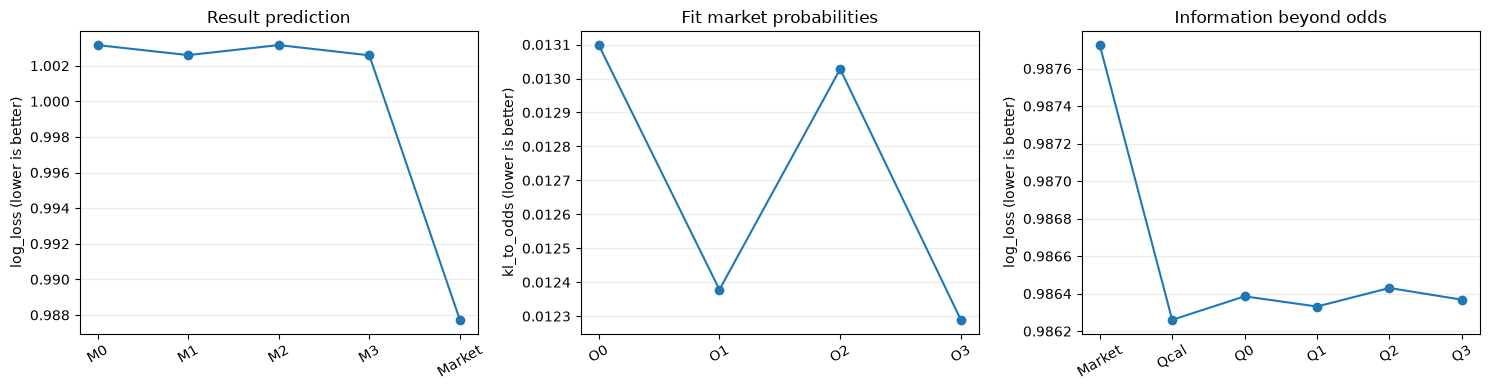

In [9]:
correlation_pairs = [(col,'home_minus_away') for col in ['recent_ppg_diff','recent_gd_diff','h2h_ppg_diff','h2h_gd']]
correlation_pairs += [('recent_draw_rate_mean','draw_probability'),('h2h_draw_rate','draw_probability')]
correlation_rows = []
for label, frame in [('all_test',test)]+[(str(int(year)),test.loc[test.year.eq(year)]) for year in sorted(test.year.unique())]:
    for col, target_name in correlation_pairs:
        target_values = frame.q_H-frame.q_A if target_name=='home_minus_away' else frame.q_D
        rho = float(spearmanr(frame[col],target_values).statistic)
        correlation_rows.append({'period':label,'feature':col,'odds_target':target_name,
                                 'matches':len(frame),'spearman_rho':rho})
correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(OUT / 'odds_correlations.csv',index=False)
display(correlations.loc[correlations.period.eq('all_test')])

fig, axes = plt.subplots(1,3,figsize=(15,4))
indexed_scores = scores.set_index('model')
for ax,names,metric,title in [
    (axes[0],['M0','M1','M2','M3','Market'],'log_loss','Result prediction'),
    (axes[1],['O0','O1','O2','O3'],'kl_to_odds','Fit market probabilities'),
    (axes[2],['Market','Qcal','Q0','Q1','Q2','Q3'],'log_loss','Information beyond odds')]:
    values = indexed_scores.loc[names,metric].to_numpy()
    ax.plot(names,values,'o-')
    ax.set(title=title,ylabel=metric+' (lower is better)')
    ax.tick_params(axis='x',rotation=30)
    ax.grid(axis='y',alpha=.25)
fig.tight_layout()
fig.savefig(OUT / 'baseline_comparison.png',dpi=160)
fig.savefig(OUT / 'baseline_comparison.svg')
plt.show()


## 10. 保存结果说明和检查记录

报告区分真实赛果预测、赔率概率拟合和赔率之外的增益。结果只针对本次样本、固定五场定义、全部历史交锋和逻辑回归，不能直接推广为LSTM或其他窗口的结果。

In [10]:
def md_table(frame):
    columns = list(frame.columns)
    lines = ['| '+' | '.join(columns)+' |','| '+' | '.join(['---']*len(columns))+' |']
    for record in frame.itertuples(index=False,name=None):
        values = [f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v) for v in record]
        lines.append('| '+' | '.join(values)+' |')
    return '\n'.join(lines)


def comparison_text(left,right,metric):
    row = paired.loc[(paired.left==left)&(paired.right==right)&(paired.metric==metric)].iloc[0]
    direction = '平均损失更低' if row.difference<0 else '平均损失更高'
    stability = '区间跨0，不能说差异稳定' if row.ci_includes_zero else '该项描述性区间未跨0'
    return f'{left}相对{right}：{direction}，差值{row.difference:.6f}，95%区间[{row.ci_low:.6f}, {row.ci_high:.6f}]；{stability}。'

main_scores = scores.loc[scores.model.isin(['M0','M1','M2','M3','Market']),['model','matches','log_loss','brier','accuracy']]
market_fit = scores.loc[scores.model.str.startswith('O'),['model','matches','kl_to_odds','odds_probability_mae']]
market_increment = scores.loc[scores.model.isin(['Market','Qcal','Q0','Q1','Q2','Q3']),['model','log_loss','brier','accuracy']]
report = f"""# 第一版基线结果

近期固定5场，历史交锋使用此前全部记录，不使用时间衰减。模型是L2多分类逻辑回归；按比赛等权评价。模型输入清单见model_inputs.csv。

## 样本与划分

{md_table(split_table)}

特征历史来自{len(valid_history):,}场有效赛果；预测样本来自cleaned.csv。2025不参与拟合或评分。最终训练使用截至2022年的{len(final_train):,}场，模型固定预测2023—2024的{len(test):,}场。测试期间历史随已经发生的比赛更新。2023—2024曾在早先分析中查看，本轮不是完全未接触过的独立验证。

## 赛果预测

M0=B，M1=B+近期五场，M2=B+全部交锋，M3=B+两者。B含联赛、Elo差、交锋数量和无交锋标记。Market是原始归一化赔率。

{md_table(main_scores)}

准确率为0到1的比例；Brier为三类平方误差之和。Log Loss和Brier越小越好。

{comparison_text('M1','M2','log_loss')}

{comparison_text('M1','M0','log_loss')}

{comparison_text('M2','M0','log_loss')}

{comparison_text('M3','M1','log_loss')}

{comparison_text('M3','M2','log_loss')}

## 哪组信息更接近赔率

O0—O3的输入分别与M0—M3一致，但目标改为赔率隐含概率；不把赔率输入自身拟合模型。KL越小，预测分布越接近赔率。

{md_table(market_fit)}

{comparison_text('O1','O2','kl_to_odds')}

这是与赔率的统计关系，不能推出博彩公司实际采用的算法。

## 赔率之外是否还有帮助

Qcal仅校准赔率；Q0=Q+B，Q1=Q+B+F，Q2=Q+B+H，Q3=Q+B+F+H。历史增益与Q0比较。

{md_table(market_increment)}

{comparison_text('Q1','Q0','log_loss')}

{comparison_text('Q2','Q0','log_loss')}

{comparison_text('Q3','Q0','log_loss')}

## 描述性相关

{md_table(correlations.loc[correlations.period.eq('all_test'),['feature','odds_target','spearman_rho']])}

相关性没有控制所有混杂因素，不证明因果关系。完整年份结果见test_scores_by_year.csv，验证选择见validation_scores.csv与selection.json。

## 范围与限制

- 结论针对当前Elo完整、五场历史完整、赔率有效的筛选样本；历史记录只覆盖文件内赛事。
- Elo包含用户允许的较早历史补值，不能认为所有评分都代表最新实力。
- 交锋优势可能仍反映实力差异，不能仅据此认定战术克制。
- 28天时间块bootstrap重复1000次，按测试年分别抽样。区间是逐项描述性区间，不含重新训练／选择不确定性，没有多重比较的同时保证。
- 没有投注收益回测，预测或拟合改善不等于盈利。

![模型比较](baseline_comparison.png)
"""
(OUT / 'RESULTS.zh-CN.md').write_text(report)
assert digest(cleaned_path) == cleaned_hash
assert verify_raw() == raw_hashes
assert json.loads((OUT / 'selection.json').read_text()) == frozen_selection
for name,p in predictions.items():
    assert p.shape == (len(test),3) and np.isfinite(p).all() and np.allclose(p.sum(axis=1),1)
assert len(validation_scores) == len(model_order)*len(C_GRID)
assert len(fit_table) == len(model_order)
# 保存的模型重新载入后必须给出同样的预测。
reload_model = joblib.load(OUT / 'models/M1.joblib')
with threadpool_limits(limits=1):
    reloaded_probability = reload_model['model'].predict_proba(reload_model['preprocessor'].transform(test.iloc[:20]))
np.testing.assert_allclose(reloaded_probability,predictions['M1'][:20])
checks = {'passed':True,'fixed_recent_window':5,'models_trained':len(model_order),
          'validation_fits':len(validation_scores),'test_matches':len(test),
          'history_excludes_current_day':True,'all_valid_results_used_for_history':True,
          'synthetic_orientation_and_counterfactual_checks':True,'independent_history_checks':24,
          'soft_target_weighting_checked':True,'preprocessing_fit_only_on_training_period':True,
          'selection_frozen_before_test':True,'same_test_rows_for_all_models':True,
          'all_probabilities_valid':True,'saved_model_reload_matches':True,
          'cleaned_and_raw_files_unchanged':True,'selected_before':selection['frozen_utc'],
          'finished_utc':datetime.now(timezone.utc).isoformat()}
(OUT / 'checks.json').write_text(json.dumps(checks,ensure_ascii=False,indent=2)+'\n')
print(comparison_text('M1','M2','log_loss'))
print(comparison_text('O1','O2','kl_to_odds'))
print('全部检查通过。结果目录：',OUT)


M1相对M2：平均损失更低，差值-0.000563，95%区间[-0.001235, 0.000096]；区间跨0，不能说差异稳定。
O1相对O2：平均损失更低，差值-0.000650，95%区间[-0.000819, -0.000501]；该项描述性区间未跨0。
全部检查通过。结果目录： /home/euan_li/projects/AML/reports/baseline
